# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

Matplotlib is building the font cache; this may take a moment.


NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH) # TODO: read PATIENTS_PATH with pd.read_csv

print("Shape:", patients.shape) # TODO: print the shape and the dtypes of patients
display(patients.dtypes)  


exploratory_chart = (
    alt.Chart(patients)
    .mark_point(filled=True, size=90)
    .encode(
        x=alt.X(
            "sessions_attended:Q",
            title="Sessions attended (of 36)"
        ),
        y=alt.Y(
            "walk_distance_m:Q",
            title="Six-minute walk distance (m)",
            scale=alt.Scale(zero=False)
        ),
        color=alt.Color("program:N", title="Program"),
        shape=alt.Shape("program:N", title="Program"),
        tooltip=[
            "patient_id:N",
            "program:N",
            "sessions_attended:Q",
            "walk_distance_m:Q"
        ]
    )
    .properties(
        title="Rehabilitation Attendance and Walking Distance"
    )
)
  # TODO: the Altair scatter plot README Task 1.1 describes

# TODO: save exploratory_chart to EXPLORATORY_SPEC_PATH with .save()
exploratory_chart.save(EXPLORATORY_SPEC_PATH)

exploratory_chart

Shape: (12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

This chart touches on the relationship between the number of cardiac rehabilitation sessions attended and the distance patients can walk in six minutes. Each point represents one patient, and color and shape tell us if they participated in a home-based or center-based program. I see a positive relationship where patients who attended more sessions generally had longer walking distances because of the upward trend for both programs as x increases y increases. However, the dataset only contains 12 patients so the sample size is a bit small to draw conclusions. Other factors, such as health or motivation, could influence both attendance and walking performance too.



## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


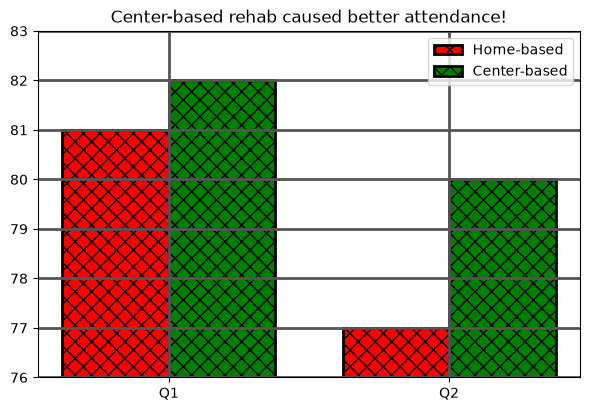

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim", "problem": "Title claims center-based rehab caused better attendance, but data show only the association", "repair": "Change title to not make a bold claim that claims causation"},  # TODO: fill in each problem and repair
    {"category": "truncated baseline", "problem": "The y-axis starts at 76 so the difference between home and center base seem wider", "repair": "start the y axis at zero so the percentages look accurate"},
    {"category": "missing unit", "problem": "The y axis has no label or unit so it's unclear what the values represent", "repair": "Labe y axis schedule sessions attend in percentages"},
    {"category": "color-only encoding", "problem": "The weird fishnet pattern is on both groups.", "repair": "Use more contrasting colors and different patterns for each group"},
    {"category": "distracting decoration", "problem": "Thick gridlines, bar outlines, random grid lines on the bar plot", "repair": "Remove unnecessary chart elements to keep things simple and easy to read"},
]


for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)


for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: Title claims center-based rehab caused better attendance, but data show only the association
    repair: Change title to not make a bold claim that claims causation
truncated baseline: The y-axis starts at 76 so the difference between home and center base seem wider
    repair: start the y axis at zero so the percentages look accurate
missing unit: The y axis has no label or unit so it's unclear what the values represent
    repair: Labe y axis schedule sessions attend in percentages
color-only encoding: The weird fishnet pattern is on both groups.
    repair: Use more contrasting colors and different patterns for each group
distracting decoration: Thick gridlines, bar outlines, random grid lines on the bar plot
    repair: Remove unnecessary chart elements to keep things simple and easy to read
unsupported claim: Title claims center-based rehab caused better attendance, but data show only the association
    repair: Change title to not make a bold claim that claims 

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

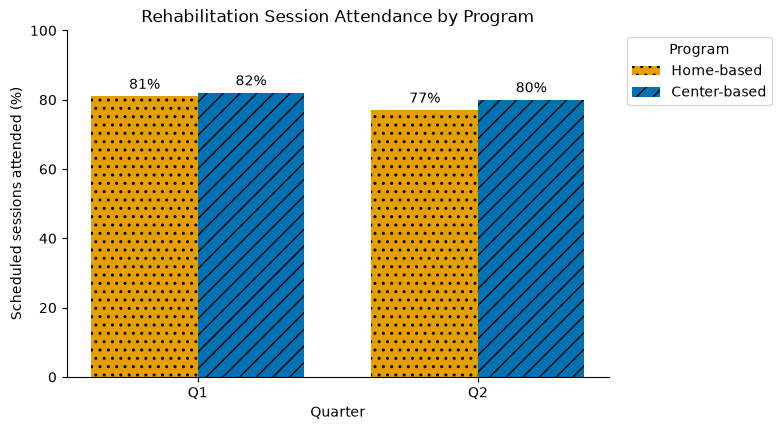

y-axis runs from 0.0 to 100.0
y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

home_bars = redesign_ax.bar(
    x - width / 2,
    home,
    width,
    label="Home-based",
    color=ORANGE,
    hatch=".."
)

center_bars = redesign_ax.bar(
    x + width / 2,
    center,
    width,
    label="Center-based",
    color=BLUE,
    hatch="//"
)

redesign_ax.bar_label(home_bars, fmt="%d%%", padding=3)
redesign_ax.bar_label(center_bars, fmt="%d%%", padding=3)

redesign_ax.set_xticks(x, quarters)
redesign_ax.set_ylim(0, 100)

redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_title("Rehabilitation Session Attendance by Program")

redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)

redesign_ax.legend(
    title="Program",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

redesign_fig.savefig(
    REDESIGN_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)


plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [7]:
followup = pd.read_csv(FOLLOWUP_PATH)  # TODO: read FOLLOWUP_PATH with pd.read_csv
# TODO: display followup
display(followup)


question = "How does % of patients meeting weekly exercise goal change across 4 follow up visits for home and center based rehab?"  # TODO: the comparison the chart should help the coordinator make
audience = "The cardiac rehab program coordinator who can use the results to identify where additional follow up support may be helpful"  # TODO: who reads the chart and what they will use it for
intended_claim = "Both programs demonstrate increase in goal achievement across visits. Center based patients have higher percentage of visits"  # TODO: the one descriptive conclusion the chart supports
y_measure = "% of patients seen who met weekly goal of 150 minutes of exercise"  # TODO: what the y-axis measures, with its unit
grain = "Each row and plotted point represents one rehabilitation program at one follow up visit"  # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "categorical",  # TODO: categorical, quantitative, ordinal, or temporal
    "visit_number": "ordinal",  # TODO
    "goal_met_pct": "quantitative",  # TODO
}

supporting_data = followup[["program", "visit_number","goal_met_pct"]].copy()  # TODO: the three plotted columns of followup
supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)
# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

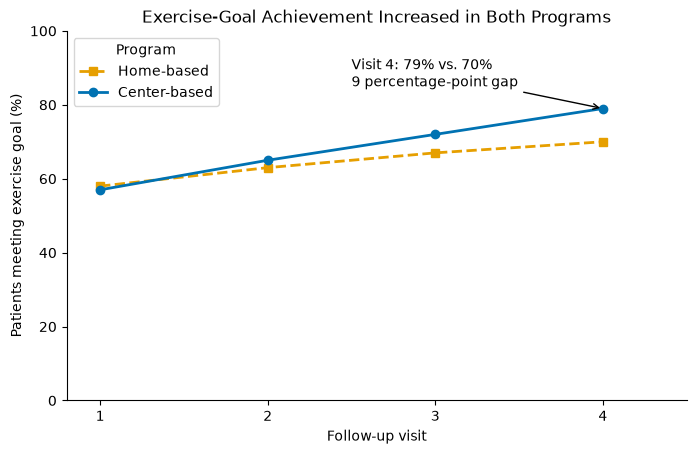

In [9]:

home_goals = supporting_data.loc[
    supporting_data["program"] == "Home-based"
]

center_goals = supporting_data.loc[
    supporting_data["program"] == "Center-based"
]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

explanatory_ax.plot(
    home_goals["visit_number"],
    home_goals["goal_met_pct"],
    color=ORANGE,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Home-based"
)

explanatory_ax.plot(
    center_goals["visit_number"],
    center_goals["goal_met_pct"],
    color=BLUE,
    marker="o",
    linestyle="-",
    linewidth=2,
    label="Center-based"
)

explanatory_ax.annotate(
    "Visit 4: 79% vs. 70%\n9 percentage-point gap",
    xy=(4, 79),
    xytext=(2.5, 85),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10
)

explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting exercise goal (%)")
explanatory_ax.set_title(
    "Exercise-Goal Achievement Increased in Both Programs"
)

explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.set_ylim(0, 100)
explanatory_ax.set_xlim(0.8, 4.5)

explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)

explanatory_ax.legend(title="Program", loc="upper left")

explanatory_fig.savefig(
    EXPLANATORY_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [10]:
text_alternative = "This line chart compares the percentage of patients meeting the weekly exercise goal of 150 minutes across four follow-up visits for home-based and center-based rehan programs. The x-axis represents follow-up visits from 1 to 4, while the y-axis represents the percentage meeting the exercise goal. Both programs show an increasing trend, with home-based patients improving from 58% to 70% and center-based patients improving from 57% to 79%. At visit 4, center-based patients had a 9-percentage-point higher rate. However, patients selected their own programs, so these differences do not establish causation. The percentages also include only patients seen at each visit, and random variation or differences in who returned could influence the results."  # TODO: one paragraph, as README Task 3.3 describes

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative
    # TODO: add question, audience, intended_claim, y_measure, grain, data_types, and text_alternative
}

# TODO: save visualization_evidence to EVIDENCE_PATH with json.dump, as the Task 2.2 cell does
with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(
        visualization_evidence,
        file,
        indent=2,
        ensure_ascii=False
    )

# TODO: write text_alternative to TEXT_ALTERNATIVE_PATH

with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)
    
with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

1. Both charts use different visual patterns to distinguish the programs without relying entirely on color. The redesigned bar chart uses different patterns. The explanatory line chart uses different markers and line styles so it is more readable.

2. The annotation points to the center-based program at visit 4, where 79% of patients met the exercise goal compared with 70% in the home-based program. The annotation describes the observed difference without suggesting that either program caused better outcomes.

3. The redesigned bar chart has the legend outside the bar chart area, while the explanatory chart uses space above the lines for the annotation. So no, no text cut off or overlapping.

4. One limitation that cannot be fixed through visualization design is the lack of random assignment. Since patients selected their rehabilitation programs, differences in patient characteristics could influence the results. For that reason, the charts cannot establish that one program causes better outcomes.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [1]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m